# EmotiSense — NLP Emotion Classification

**Project by Okasha Amir**



## 1. Import required libraries

In [29]:
import re
import string
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    log_loss
)

RANDOM_STATE = 42

sns.set_theme(style="whitegrid")
pd.set_option("display.max_colwidth", 120)

## 2. Load the Kaggle dataset



In [30]:
DATA_FILE = Path("train.txt.zip")



df = pd.read_csv(
    DATA_FILE,
    sep=";",
    header=None,
    names=["text", "emotion"]
)

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (16000, 2)


,text,emotion
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned hopeful just from being around someone who cares and is awake,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplace i will know that it is still on the property,love
4,i am feeling grouchy,anger


## 3. Inspect and validate the dataset

In [31]:
print("Missing values before cleaning:")
print(df.isnull().sum())

print("\nEmotion labels:")
print(df["emotion"].value_counts(dropna=False))

print("\nNumber of unique text entries:", df["text"].nunique())

Missing values before cleaning:
text       0
emotion    0
dtype: int64

Emotion labels:
emotion
joy         5362
sadness     4666
anger       2159
fear        1937
love        1304
surprise     572
Name: count, dtype: int64

Number of unique text entries: 15969


## 4. Clean the text consistently


In [32]:
def clean_text(text):
    """Clean one English text string; keep all words/stopwords."""
    text = str(text).lower()

    # Remove punctuation (same behavior as the current Streamlit UI)
    text = text.translate(str.maketrans("", "", string.punctuation))

    # Remove digits
    text = "".join(char for char in text if not char.isdigit())

    # Remove emojis and other non-ASCII characters
    text = "".join(char for char in text if char.isascii())

    # Normalize repeated spaces
    text = " ".join(text.split())

    return text


# Drop rows with missing values, normalize labels, and clean text.
df = df.dropna(subset=["text", "emotion"]).copy()
df["emotion"] = df["emotion"].astype(str).str.strip().str.lower()
df["text"] = df["text"].apply(clean_text)

# Remove empty text entries.
df = df[df["text"].str.len() > 0].copy()

# Remove exact duplicated text-label pairs.
before_deduplication = len(df)
df = df.drop_duplicates(subset=["text", "emotion"]).reset_index(drop=True)
print("Exact duplicate rows removed:", before_deduplication - len(df))

# Identify texts that have conflicting emotion labels.
label_counts_per_text = df.groupby("text")["emotion"].nunique()
ambiguous_texts = label_counts_per_text[label_counts_per_text > 1].index

print("Texts with conflicting labels:", len(ambiguous_texts))

# Remove ambiguous identical texts so the same text cannot appear
# with conflicting labels in both training and testing.
if len(ambiguous_texts) > 0:
    df = df[~df["text"].isin(ambiguous_texts)].copy()

df = df.reset_index(drop=True)

print("Cleaned dataset shape:", df.shape)
display(df.head())

Exact duplicate rows removed: 1
Texts with conflicting labels: 30
Cleaned dataset shape: (15939, 2)


,text,emotion
0,i didnt feel humiliated,sadness
1,i can go from feeling so hopeless to so damned hopeful just from being around someone who cares and is awake,sadness
2,im grabbing a minute to post i feel greedy wrong,anger
3,i am ever feeling nostalgic about the fireplace i will know that it is still on the property,love
4,i am feeling grouchy,anger


## 5. Encode the emotion labels



In [33]:
label_encoder = LabelEncoder()

df["emotion"] = label_encoder.fit_transform(df["emotion"])

emotion_numbers = {
    str(emotion): int(number)
    for number, emotion in enumerate(label_encoder.classes_)
}

emotion_labels = {
    int(number): str(emotion)
    for number, emotion in enumerate(label_encoder.classes_)
}

print("Emotion-to-number mapping:")
print(emotion_numbers)

print("\nNumber of emotion classes:", len(emotion_labels))
print("Emotion names:", list(label_encoder.classes_))

if len(emotion_labels) != 6:
    print("WARNING: This dataset does not contain exactly six emotion classes.")

Emotion-to-number mapping:
{'anger': 0, 'fear': 1, 'joy': 2, 'love': 3, 'sadness': 4, 'surprise': 5}

Number of emotion classes: 6
Emotion names: ['anger', 'fear', 'joy', 'love', 'sadness', 'surprise']


## 6. Examine the emotion distribution



,Number of samples
emotion,
anger,2152
fear,1926
joy,5345
love,1289
sadness,4662
surprise,565


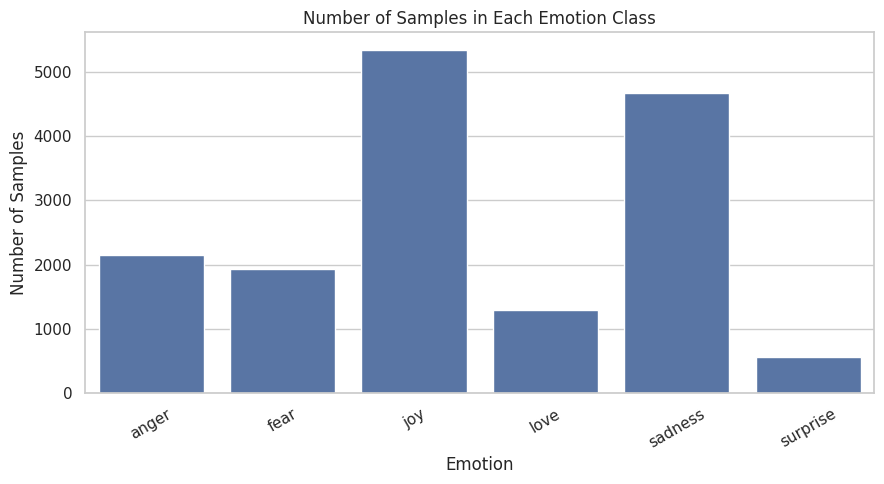

In [34]:
emotion_counts = (
    df["emotion"]
    .map(emotion_labels)
    .value_counts()
    .reindex(list(label_encoder.classes_), fill_value=0)
)

display(emotion_counts.rename("Number of samples").to_frame())

plt.figure(figsize=(9, 5))
sns.barplot(x=emotion_counts.index, y=emotion_counts.values)
plt.title("Number of Samples in Each Emotion Class")
plt.xlabel("Emotion")
plt.ylabel("Number of Samples")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## 7. Split the data into training and testing sets


In [35]:
X = df["text"].astype(str)
y = df["emotion"].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

print("\nTraining emotion distribution:")
print(y_train.map(emotion_labels).value_counts(normalize=True).round(3))

print("\nTesting emotion distribution:")
print(y_test.map(emotion_labels).value_counts(normalize=True).round(3))

Training samples: 12751
Testing samples: 3188

Training emotion distribution:
emotion
joy         0.335
sadness     0.292
anger       0.135
fear        0.121
love        0.081
surprise    0.035
Name: proportion, dtype: float64

Testing emotion distribution:
emotion
joy         0.335
sadness     0.293
anger       0.135
fear        0.121
love        0.081
surprise    0.035
Name: proportion, dtype: float64


## 8. Baseline 1 — Bag of Words + Multinomial Naive Bayes

In [36]:
bow_vectorizer = CountVectorizer(
    ngram_range=(1, 1),
    min_df=1
)

X_train_bow = bow_vectorizer.fit_transform(X_train)
X_test_bow = bow_vectorizer.transform(X_test)

bow_nb_model = MultinomialNB()
bow_nb_model.fit(X_train_bow, y_train)

pred_bow = bow_nb_model.predict(X_test_bow)

bow_accuracy = accuracy_score(y_test, pred_bow)
print(f"Bag of Words + Naive Bayes accuracy: {bow_accuracy:.4f}")

Bag of Words + Naive Bayes accuracy: 0.7450


## 9. Baseline 2 — TF-IDF + Multinomial Naive Bayes

In [37]:
tfidf_nb_vectorizer = TfidfVectorizer(
    ngram_range=(1, 1),
    min_df=1,
    sublinear_tf=True
)

X_train_tfidf_nb = tfidf_nb_vectorizer.fit_transform(X_train)
X_test_tfidf_nb = tfidf_nb_vectorizer.transform(X_test)

tfidf_nb_model = MultinomialNB()
tfidf_nb_model.fit(X_train_tfidf_nb, y_train)

pred_tfidf_nb = tfidf_nb_model.predict(X_test_tfidf_nb)

tfidf_nb_accuracy = accuracy_score(y_test, pred_tfidf_nb)
print(f"TF-IDF + Naive Bayes accuracy: {tfidf_nb_accuracy:.4f}")

TF-IDF + Naive Bayes accuracy: 0.6302


## 10. Baseline 3 — TF-IDF + Logistic Regression



In [38]:
baseline_vectorizer = TfidfVectorizer(
    ngram_range=(1, 1),
    min_df=1,
    sublinear_tf=True
)

X_train_baseline = baseline_vectorizer.fit_transform(X_train)
X_test_baseline = baseline_vectorizer.transform(X_test)

baseline_logistic = LogisticRegression(
    max_iter=2000,
    C=1.0,
    random_state=RANDOM_STATE
)

baseline_logistic.fit(X_train_baseline, y_train)
pred_baseline_logistic = baseline_logistic.predict(X_test_baseline)

baseline_logistic_accuracy = accuracy_score(
    y_test,
    pred_baseline_logistic
)

print(
    "Baseline TF-IDF + Logistic Regression accuracy:",
    round(baseline_logistic_accuracy, 4)
)

Baseline TF-IDF + Logistic Regression accuracy: 0.8526


## 11. Tune Logistic Regression with cross-validation



In [39]:
logistic_pipeline = Pipeline([
    (
        "tfidf",
        TfidfVectorizer(
            sublinear_tf=True,
            strip_accents="unicode",
            max_df=0.98,
            max_features=50000
        )
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=3000,
            random_state=RANDOM_STATE
        )
    )
])

param_grid = {
    "tfidf__ngram_range": [(1, 1), (1, 2)],
    "tfidf__min_df": [1, 2],
    "classifier__C": [0.5, 1.0, 2.0],
    "classifier__class_weight": [None, "balanced"]
}

cv_strategy = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

grid_search = GridSearchCV(
    estimator=logistic_pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv_strategy,
    n_jobs=-1,
    verbose=1,
    refit=True
)

grid_search.fit(X_train, y_train)

best_pipeline = grid_search.best_estimator_

print("Best cross-validation macro F1:", round(grid_search.best_score_, 4))
print("\nBest parameters:")
print(grid_search.best_params_)

Fitting 3 folds for each of 24 candidates, totalling 72 fits
Best cross-validation macro F1: 0.8393

Best parameters:
{'classifier__C': 2.0, 'classifier__class_weight': 'balanced', 'tfidf__min_df': 2, 'tfidf__ngram_range': (1, 1)}


## 12. Evaluate the tuned Logistic Regression model

The test set is used here for the first final evaluation after model selection.

In [40]:
best_vectorizer = best_pipeline.named_steps["tfidf"]
best_logistic_model = best_pipeline.named_steps["classifier"]

X_train_tfidf = best_vectorizer.transform(X_train)
X_test_tfidf = best_vectorizer.transform(X_test)

pred_tuned_logistic = best_pipeline.predict(X_test)

tuned_logistic_accuracy = accuracy_score(
    y_test,
    pred_tuned_logistic
)

print("Tuned Logistic Regression accuracy:", round(tuned_logistic_accuracy, 4))

Tuned Logistic Regression accuracy: 0.8877


:## 13. For Benchmark — Linear SVM



In [41]:
svm_model = LinearSVC(
    C=1.0,
    class_weight=None,
    random_state=RANDOM_STATE
)

svm_model.fit(X_train_tfidf, y_train)
pred_svm = svm_model.predict(X_test_tfidf)

svm_accuracy = accuracy_score(y_test, pred_svm)
print("Linear SVM accuracy:", round(svm_accuracy, 4))

Linear SVM accuracy: 0.9015


## 14. Calibrate Logistic Regression probabilities



In [42]:
best_C = grid_search.best_params_["classifier__C"]
best_class_weight = grid_search.best_params_["classifier__class_weight"]

logistic_for_calibration = LogisticRegression(
    C=best_C,
    class_weight=best_class_weight,
    max_iter=3000,
    random_state=RANDOM_STATE
)

calibrated_model = CalibratedClassifierCV(
    estimator=logistic_for_calibration,
    method="sigmoid",
    cv=3
)

calibrated_model.fit(X_train_tfidf, y_train)

final_predictions = calibrated_model.predict(X_test_tfidf)
final_probabilities = calibrated_model.predict_proba(X_test_tfidf)

final_accuracy = accuracy_score(y_test, final_predictions)

print("Calibrated model accuracy:", round(final_accuracy, 4))

Calibrated model accuracy: 0.8858


In [43]:
# ==========================================
# CALIBRATED LINEAR SVM
# ==========================================

from sklearn.svm import LinearSVC
from sklearn.calibration import CalibratedClassifierCV

# Create SVM classifier
svm_base = LinearSVC(
    C=1.0,
    class_weight=None,
    max_iter=5000,
    random_state=RANDOM_STATE
)

# Add probability calibration
svm_calibrated = CalibratedClassifierCV(
    estimator=svm_base,
    method="sigmoid",
    cv=3
)

# Train the model
svm_calibrated.fit(X_train_tfidf, y_train)

# Make predictions
svm_calibrated_predictions = svm_calibrated.predict(
    X_test_tfidf
)

# Get probabilities
svm_calibrated_probabilities = (
    svm_calibrated.predict_proba(X_test_tfidf)
)

# Evaluate accuracy
svm_calibrated_accuracy = accuracy_score(
    y_test,
    svm_calibrated_predictions
)

# Evaluate precision, recall and macro F1
svm_precision, svm_recall, svm_macro_f1, _ = (
    precision_recall_fscore_support(
        y_test,
        svm_calibrated_predictions,
        average="macro",
        zero_division=0
    )
)

# Weighted F1
svm_weighted_f1 = (
    precision_recall_fscore_support(
        y_test,
        svm_calibrated_predictions,
        average="weighted",
        zero_division=0
    )[2]
)

print("CALIBRATED LINEAR SVM RESULTS")

print("Accuracy:", round(svm_calibrated_accuracy * 100, 2), "%")
print("Macro Precision:", round(svm_precision * 100, 2), "%")
print("Macro Recall:", round(svm_recall * 100, 2), "%")
print("Macro F1:", round(svm_macro_f1 * 100, 2), "%")
print("Weighted F1:", round(svm_weighted_f1 * 100, 2), "%")

CALIBRATED LINEAR SVM RESULTS
Accuracy: 90.21 %
Macro Precision: 87.37 %
Macro Recall: 85.4 %
Macro F1: 86.28 %
Weighted F1: 90.14 %


## 15. Full classification report



In [44]:
class_ids = list(range(len(label_encoder.classes_)))
class_names = [str(name) for name in label_encoder.classes_]

print(
    classification_report(
        y_test,
        final_predictions,
        labels=class_ids,
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

final_macro_f1 = precision_recall_fscore_support(
    y_test,
    final_predictions,
    average="macro",
    zero_division=0
)[2]

final_weighted_f1 = precision_recall_fscore_support(
    y_test,
    final_predictions,
    average="weighted",
    zero_division=0
)[2]

final_log_loss = log_loss(
    y_test,
    final_probabilities,
    labels=calibrated_model.classes_
)

print("Final accuracy:", round(final_accuracy, 4))
print("Final macro F1:", round(final_macro_f1, 4))
print("Final weighted F1:", round(final_weighted_f1, 4))
print("Final log loss (lower is better):", round(final_log_loss, 4))

              precision    recall  f1-score   support

       anger     0.8515    0.9070    0.8784       430
        fear     0.8615    0.8727    0.8671       385
         joy     0.9090    0.9065    0.9077      1069
        love     0.7860    0.8256    0.8053       258
     sadness     0.9305    0.8896    0.9096       933
    surprise     0.7748    0.7611    0.7679       113

    accuracy                         0.8858      3188
   macro avg     0.8522    0.8604    0.8560      3188
weighted avg     0.8871    0.8858    0.8862      3188

Final accuracy: 0.8858
Final macro F1: 0.856
Final weighted F1: 0.8862
Final log loss (lower is better): 0.3494


## 16. Confusion matrix

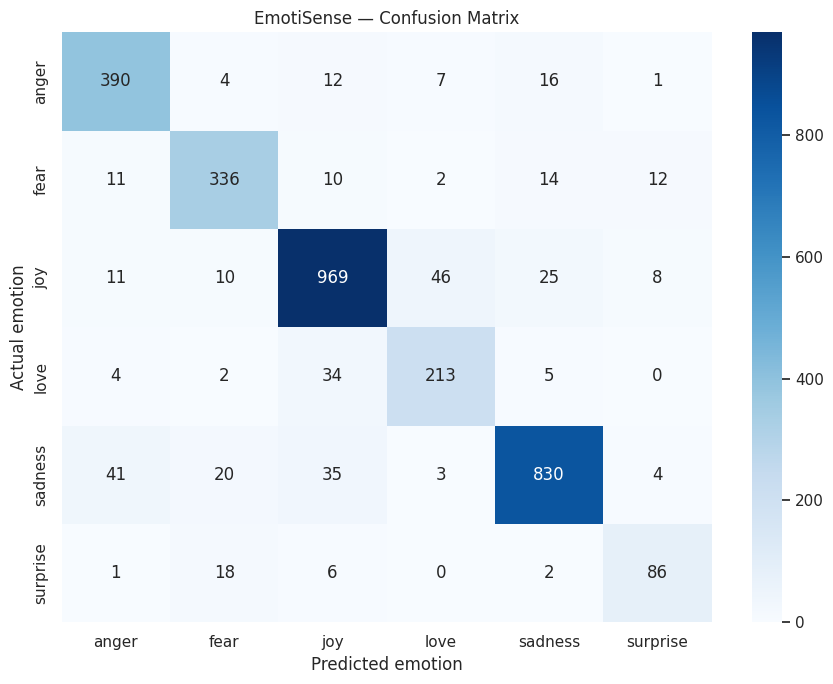

In [45]:
cm = confusion_matrix(
    y_test,
    final_predictions,
    labels=class_ids
)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.title("EmotiSense — Confusion Matrix")
plt.xlabel("Predicted emotion")
plt.ylabel("Actual emotion")
plt.tight_layout()
plt.show()

## 17. Compare all models



In [46]:
def get_model_metrics(y_true, y_pred, model_name):
    precision, recall, macro_f1, _ = precision_recall_fscore_support(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    weighted_f1 = precision_recall_fscore_support(
        y_true,
        y_pred,
        average="weighted",
        zero_division=0
    )[2]

    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro Precision": precision,
        "Macro Recall": recall,
        "Macro F1": macro_f1,
        "Weighted F1": weighted_f1
    }


comparison = pd.DataFrame([
    get_model_metrics(y_test, pred_bow, "Bag of Words + Naive Bayes"),
    get_model_metrics(y_test, pred_tfidf_nb, "TF-IDF + Naive Bayes"),
    get_model_metrics(y_test, pred_baseline_logistic, "Baseline Logistic Regression"),
    get_model_metrics(y_test, pred_tuned_logistic, "Tuned Logistic Regression"),
    get_model_metrics(y_test, pred_svm, "Linear SVM"),
    get_model_metrics(y_test, final_predictions, "Calibrated Logistic Regression")
])

display(
    comparison.sort_values(
        by="Macro F1",
        ascending=False
    ).style.format({
        "Accuracy": "{:.2%}",
        "Macro Precision": "{:.2%}",
        "Macro Recall": "{:.2%}",
        "Macro F1": "{:.2%}",
        "Weighted F1": "{:.2%}"
    })
)

,Model,Accuracy,Macro Precision,Macro Recall,Macro F1,Weighted F1
4,Linear SVM,90.15%,87.51%,84.87%,86.04%,90.04%
3,Tuned Logistic Regression,88.77%,83.66%,88.93%,85.91%,88.96%
5,Calibrated Logistic Regression,88.58%,85.22%,86.04%,85.60%,88.62%
2,Baseline Logistic Regression,85.26%,86.86%,73.73%,78.04%,84.56%
0,Bag of Words + Naive Bayes,74.50%,85.91%,53.09%,55.91%,70.91%
1,TF-IDF + Naive Bayes,63.02%,68.79%,36.22%,33.37%,53.36%


## 18. Inspect prediction probabilities for one test example



In [47]:
example_index = 0

example_text = X_test.iloc[example_index]
actual_class = int(y_test.iloc[example_index])

example_vector = best_vectorizer.transform([example_text])
example_probabilities = calibrated_model.predict_proba(example_vector)[0]
predicted_class = int(calibrated_model.predict(example_vector)[0])

probability_table = pd.DataFrame({
    "Emotion": [
        emotion_labels[int(class_id)]
        for class_id in calibrated_model.classes_
    ],
    "Estimated probability": example_probabilities
}).sort_values(
    "Estimated probability",
    ascending=False
).reset_index(drop=True)

print("Text:", example_text)
print("Actual emotion:", emotion_labels[actual_class])
print("Predicted emotion:", emotion_labels[predicted_class])

display(
    probability_table.style.format({
        "Estimated probability": "{:.2%}"
    })
)

Text: im feeling pretty depressed and i think its spiraling
Actual emotion: sadness
Predicted emotion: sadness


,Emotion,Estimated probability
0,sadness,65.13%
1,joy,33.54%
2,anger,0.59%
3,surprise,0.58%
4,fear,0.13%
5,love,0.03%


In [48]:
# ==========================================
# SELECT BEST MODEL
# ==========================================

if (svm_macro_f1, svm_calibrated_accuracy) > (
    final_macro_f1, final_accuracy
):

    selected_model = svm_calibrated

    selected_accuracy = svm_calibrated_accuracy

    selected_macro_f1 = svm_macro_f1

    selected_weighted_f1 = svm_weighted_f1

    selected_algorithm = "Calibrated Linear SVM"

else:

    selected_model = calibrated_model

    selected_accuracy = final_accuracy

    selected_macro_f1 = final_macro_f1

    selected_weighted_f1 = final_weighted_f1

    selected_algorithm = "Calibrated Logistic Regression"


print("================================")
print("FINAL SELECTED MODEL")
print("================================")

print("Algorithm:", selected_algorithm)

print("Accuracy:", round(selected_accuracy * 100, 2), "%")

print("Macro F1:", round(selected_macro_f1 * 100, 2), "%")

print("Weighted F1:", round(selected_weighted_f1 * 100, 2), "%")

FINAL SELECTED MODEL
Algorithm: Calibrated Linear SVM
Accuracy: 90.21 %
Macro F1: 86.28 %
Weighted F1: 90.14 %


## 19. Save the model



In [49]:
# ==========================================
# SAVE FINAL SELECTED MODEL
# ==========================================

model_package = {

    "vectorizer": best_vectorizer,

    "model": selected_model,

    "emotion_labels": emotion_labels,

    "stop_words": [],

    "accuracy": float(selected_accuracy),

    "macro_f1": float(selected_macro_f1),

    "weighted_f1": float(selected_weighted_f1),

    "algorithm": selected_algorithm

}

joblib.dump(
    model_package,
    "emotion_model.joblib"
)

print("Model saved successfully!")

print("Selected algorithm:", selected_algorithm)

print("Accuracy:", selected_accuracy)

print("File location:", Path("emotion_model.joblib").resolve())

Model saved successfully!
Selected algorithm: Calibrated Linear SVM
Accuracy: 0.9021329987452948
File location: /content/emotion_model.joblib


## 20. Verify the saved model package



In [50]:
saved_package = joblib.load("emotion_model.joblib")

required_keys = [
    "vectorizer",
    "model",
    "emotion_labels",
    "stop_words",
    "accuracy"
]

for key in required_keys:
    print(f"{key}: {'OK' if key in saved_package else 'MISSING'}")

test_sentence = "I am not happy with what happened"

# Apply exactly the same clean_text function used for training.
cleaned_sentence = clean_text(test_sentence)
sentence_vector = saved_package["vectorizer"].transform([cleaned_sentence])

predicted_id = int(saved_package["model"].predict(sentence_vector)[0])
predicted_name = saved_package["emotion_labels"][predicted_id]
predicted_scores = saved_package["model"].predict_proba(sentence_vector)[0]

print("\nTest sentence:", test_sentence)
print("Cleaned sentence:", cleaned_sentence)
print("Predicted emotion:", predicted_name)

test_scores = pd.DataFrame({
    "Emotion": [
        saved_package["emotion_labels"][int(class_id)]
        for class_id in saved_package["model"].classes_
    ],
    "Probability": predicted_scores
}).sort_values("Probability", ascending=False)

display(test_scores.style.format({"Probability": "{:.2%}"}))

vectorizer: OK
model: OK
emotion_labels: OK
stop_words: OK
accuracy: OK

Test sentence: I am not happy with what happened
Cleaned sentence: i am not happy with what happened
Predicted emotion: joy


,Emotion,Probability
2,joy,78.40%
0,anger,18.16%
1,fear,1.72%
4,sadness,1.44%
5,surprise,0.16%
3,love,0.13%


## 21. Download the model



In [51]:
try:
    from google.colab import files
    files.download("emotion_model.joblib")
except ImportError:
    print("Not running in Google Colab.")
    print("Find emotion_model.joblib here:", Path("emotion_model.joblib").resolve())

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [52]:
import joblib
import os

# Load saved model
saved_package = joblib.load("emotion_model.joblib")

# Verify important information
print("========== MODEL VERIFICATION ==========")

print("Algorithm:", saved_package.get("algorithm"))

print("Model Object:", type(saved_package["model"]).__name__)

print("Accuracy:", saved_package.get("accuracy"))

print("Macro F1:", saved_package.get("macro_f1"))

print("Weighted F1:", saved_package.get("weighted_f1"))

print("Emotion Labels:", saved_package["emotion_labels"])

print("Stopwords:", len(saved_package["stop_words"]))

print("File Size:",
      round(os.path.getsize("emotion_model.joblib") / 1024, 2),
      "KB")

print("========================================")

========== MODEL VERIFICATION ==========
Algorithm: Calibrated Linear SVM
Model Object: CalibratedClassifierCV
Accuracy: 0.9021329987452948
Macro F1: 0.8627763641808001
Weighted F1: 0.9014203895084711
Emotion Labels: {0: 'anger', 1: 'fear', 2: 'joy', 3: 'love', 4: 'sadness', 5: 'surprise'}
Stopwords: 0
File Size: 1120.16 KB
